In [11]:
import streamlit as st
import pandas as pd
import numpy as np
import joblib
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

In [12]:
df = pd.read_csv('Sleep_health_and_lifestyle_dataset.csv')

In [13]:
df['Sleep Disorder'] = df['Sleep Disorder'].fillna('None')
df['BMI Category'] = df['BMI Category'].replace({'Normal Weight': 'Normal'})
df = df.drop(columns=['Person ID'])

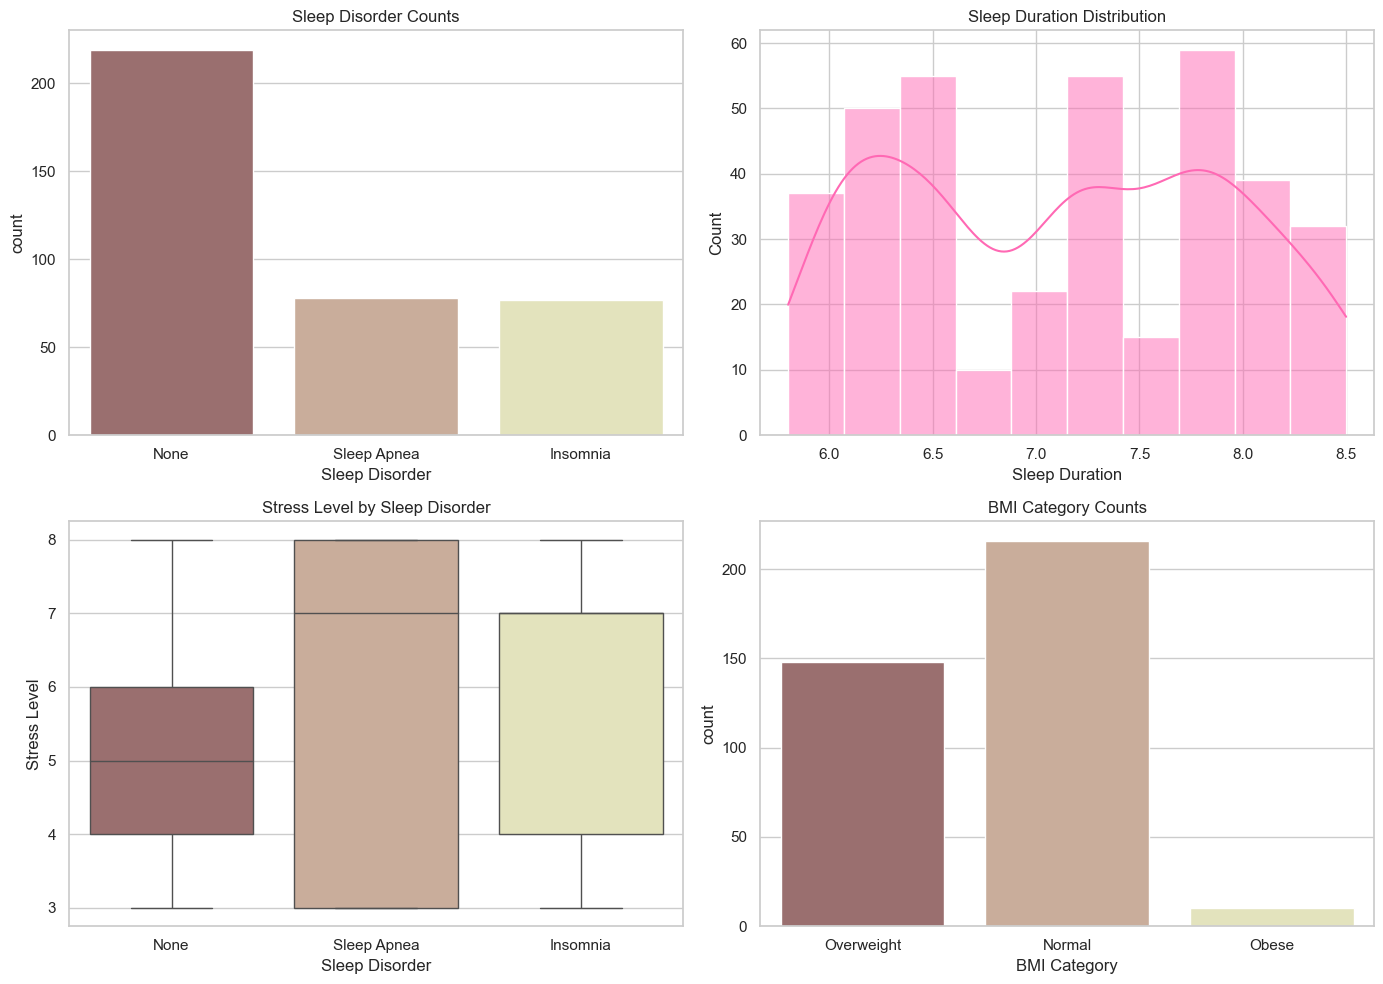

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns


sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))


sns.countplot(data=df, x='Sleep Disorder', hue='Sleep Disorder', ax=axes[0, 0], palette='pink', legend=False)
axes[0, 0].set_title('Sleep Disorder Counts')


sns.histplot(df['Sleep Duration'], kde=True, ax=axes[0, 1], color='hotpink')
axes[0, 1].set_title('Sleep Duration Distribution')


sns.boxplot(data=df, x='Sleep Disorder', y='Stress Level', hue='Sleep Disorder', ax=axes[1, 0], palette='pink', legend=False)
axes[1, 0].set_title('Stress Level by Sleep Disorder')


sns.countplot(data=df, x='BMI Category', hue='BMI Category', ax=axes[1, 1], palette='pink', legend=False)
axes[1, 1].set_title('BMI Category Counts')

plt.tight_layout()
plt.show()

In [15]:
bp_split = df['Blood Pressure'].str.split('/', expand=True).astype(int)
df['Systolic_BP'] = bp_split[0]
df['Diastolic_BP'] = bp_split[1]
df = df.drop(columns=['Blood Pressure'])

In [16]:
df['Gender'] = df['Gender'].map({'Male': 0, 'Female': 1})
df['BMI Category'] = df['BMI Category'].map({'Normal': 0, 'Overweight': 1, 'Obese': 2})
df['Sleep Disorder'] = df['Sleep Disorder'].map({'None': 0, 'Insomnia': 1, 'Sleep Apnea': 2})

In [17]:
feature_cols = [
'Gender', 'Age', 'Sleep Duration', 'Quality of Sleep',
'Physical Activity Level', 'Stress Level', 'BMI Category',
'Systolic_BP', 'Diastolic_BP', 'Heart Rate', 'Daily Steps'
]

X = df[feature_cols]
y = df['Sleep Disorder']

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.2, random_state=42, stratify=y
)

In [19]:
continuous_cols = [
'Age', 'Sleep Duration', 'Physical Activity Level',
'Stress Level', 'Systolic_BP', 'Diastolic_BP',
'Heart Rate', 'Daily Steps'
]

scaler = StandardScaler()
X_train[continuous_cols] = scaler.fit_transform(X_train[continuous_cols])
X_test[continuous_cols] = scaler.transform(X_test[continuous_cols])

In [20]:
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)

gb_model = GradientBoostingClassifier(random_state=42)
gb_model.fit(X_train, y_train)

rf_preds = rf_model.predict(X_test)
gb_preds = gb_model.predict(X_test)

In [21]:
print("random forest accuracy")
print(accuracy_score(y_test, rf_preds))

print("random forest f1 score")
print(f1_score(y_test, rf_preds, average='weighted'))

print("random forest classification report")
print(classification_report(y_test, rf_preds))

random forest accuracy
0.9333333333333333
random forest f1 score
0.9342090859332237
random forest classification report
              precision    recall  f1-score   support

           0       1.00      0.98      0.99        44
           1       0.92      0.80      0.86        15
           2       0.79      0.94      0.86        16

    accuracy                           0.93        75
   macro avg       0.90      0.90      0.90        75
weighted avg       0.94      0.93      0.93        75



In [22]:
print("gradient boosting accuracy")
print(accuracy_score(y_test, gb_preds))

print("gradient boosting f1 score")
print(f1_score(y_test, gb_preds, average='weighted'))

print("gradient boosting classification report")
print(classification_report(y_test, gb_preds))

gradient boosting accuracy
0.9066666666666666
gradient boosting f1 score
0.9080041797283176
gradient boosting classification report
              precision    recall  f1-score   support

           0       1.00      0.98      0.99        44
           1       0.80      0.80      0.80        15
           2       0.76      0.81      0.79        16

    accuracy                           0.91        75
   macro avg       0.85      0.86      0.86        75
weighted avg       0.91      0.91      0.91        75



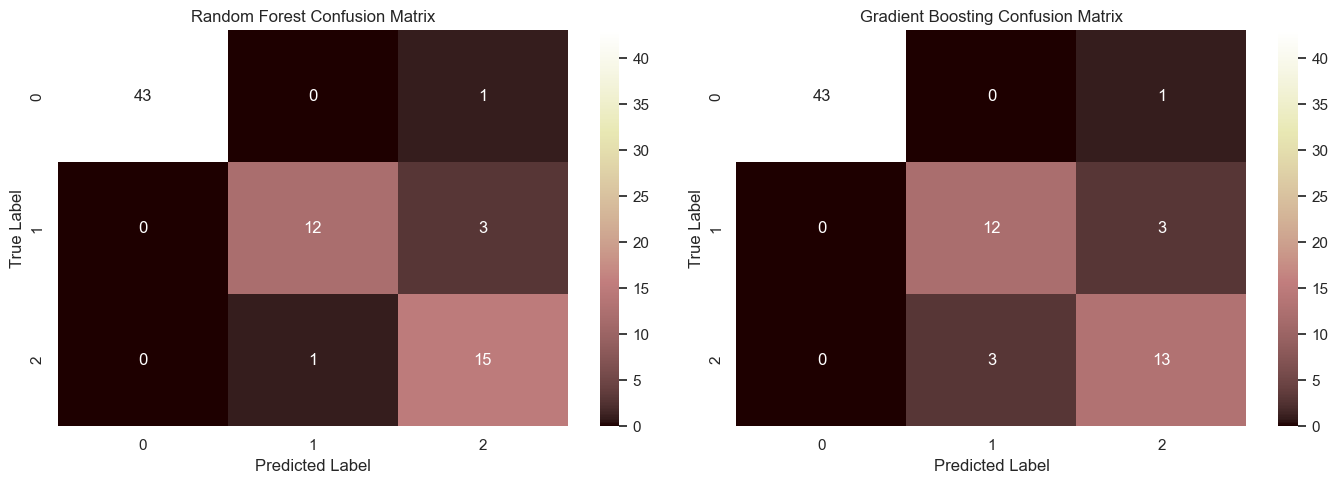

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(
    confusion_matrix(y_test, rf_preds), 
    annot=True, 
    fmt='d', 
    cmap='pink', 
    ax=axes[0]
)
axes[0].set_title('Random Forest Confusion Matrix')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

sns.heatmap(
    confusion_matrix(y_test, gb_preds), 
    annot=True, 
    fmt='d', 
    cmap='pink', 
    ax=axes[1]
)
axes[1].set_title('Gradient Boosting Confusion Matrix')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

plt.tight_layout()
plt.show()

In [24]:
import joblib

joblib.dump(rf_model, 'sleep_disorder_rf_model.pkl')
joblib.dump(scaler, 'feature_scaler.pkl')

print("models and scaler saved successfully")

models and scaler saved successfully
